In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

train = pd.read_csv('sample_data/california_housing_train.csv')
test = pd.read_csv('sample_data/california_housing_test.csv')

print(train.shape, test.shape)
train.head()

(17000, 9) (3000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


EDA

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


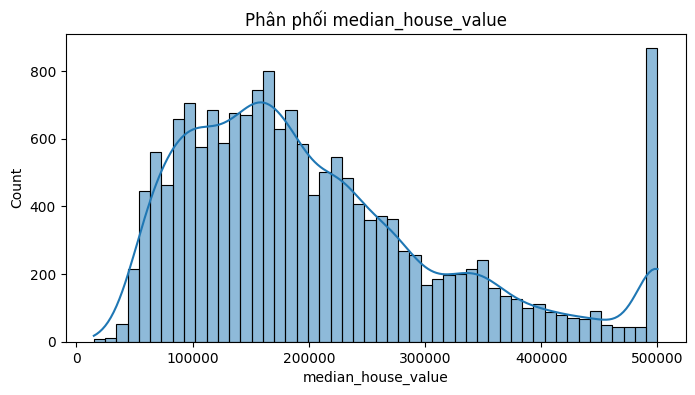

median_house_value    1.000000
median_income         0.691871
total_rooms           0.130991
housing_median_age    0.106758
households            0.061031
total_bedrooms        0.045783
population           -0.027850
longitude            -0.044982
latitude             -0.144917
Name: median_house_value, dtype: float64


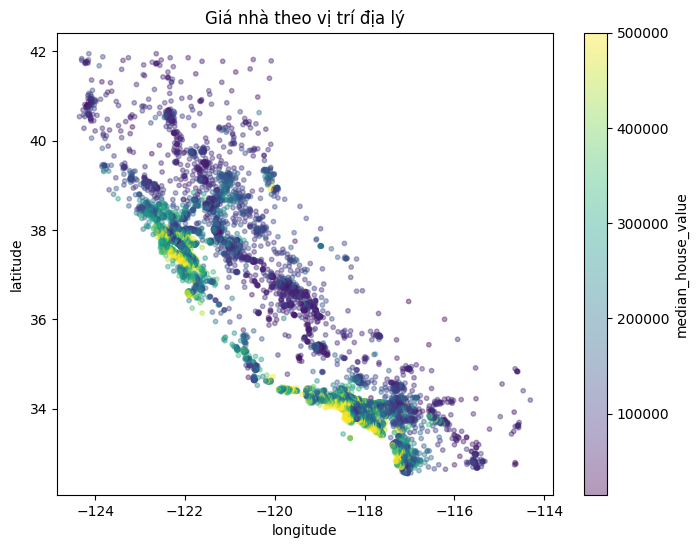

In [ ]:
train.info()
train.describe()

# Phân phối target
plt.figure(figsize=(8,4))
sns.histplot(train['median_house_value'], bins=50, kde=True)
plt.title('Phân phối median_house_value')
plt.show()

# Tương quan với target
corr = train.corr(numeric_only=True)['median_house_value'].sort_values(ascending=False)
print(corr)

# Scatter theo toạ độ, tô màu theo giá
plt.figure(figsize=(8,6))
sc = plt.scatter(train['longitude'], train['latitude'],
                  c=train['median_house_value'], cmap='viridis',
                  alpha=0.4, s=10)
plt.colorbar(sc, label='median_house_value')
plt.xlabel('longitude'); plt.ylabel('latitude')
plt.title('Giá nhà theo vị trí địa lý')
plt.show()

Xử lý missing + feature engineering

In [ ]:
def preprocess(df):
    df = df.copy()


    # Feature engineering — tạo tỉ lệ có ý nghĩa hơn thay vì dùng tổng thô
    df['rooms_per_household'] = df['total_rooms'] / df['households']
    df['population_per_household'] = df['population'] / df['households']

    return df

train_fe = preprocess(train)
test_fe = preprocess(test)

train_fe.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,population_per_household
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0,11.889831,2.150424
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0,16.522678,2.438445
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0,6.153846,2.846154
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0,6.641593,2.278761
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0,5.549618,2.381679


4 — Tách X, y và chuẩn hoá

In [ ]:
target = 'median_house_value'
features = [c for c in train_fe.columns if c != target]

X_train, y_train = train_fe[features], train_fe[target]
X_test, y_test = test_fe[features], test_fe[target]

# Log-transform target vì giá nhà thường lệch phải
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

5 — Train nhiều model + so sánh bằng cross-validation

In [ ]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train_log,
                              cv=kf, scoring='neg_root_mean_squared_error')
    results[name] = -scores
    print(f"{name:20s} RMSE(log) CV: {-scores.mean():.4f} (+/- {scores.std():.4f})")

Linear Regression    RMSE(log) CV: 0.3495 (+/- 0.0227)
Random Forest        RMSE(log) CV: 0.2324 (+/- 0.0037)


6 — Train model tốt nhất trên toàn bộ train, đánh giá trên test

In [ ]:
best_model = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
best_model.fit(X_train_scaled, y_train_log)

y_pred_log = best_model.predict(X_test_scaled)
y_pred = np.expm1(y_pred_log)  # đảo log-transform

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:,.0f}")
print(f"MAE:  {mae:,.0f}")
print(f"R2:   {r2:.4f}")

RMSE: 51,749
MAE:  31,863
R2:   0.7906
